# 02 · Análise exploratória da logística

Esta análise examina a relação entre a nota individual de satisfação (`nps_score`) e prazo previsto, atraso, tentativas de entrega e frete. A unidade é um pedido por cliente. A fonte é a base preparada em `data/processed/nps_tratado.csv`, gerada pelo notebook 01; o CSV original permanece intacto.

A classificação adotada no projeto é: detrator `< 7`, neutro `7 a < 9`, promotor `>= 9`, sem arredondamento. O índice NPS é a porcentagem de promotores menos a de detratores. Comparações entre grupos descrevem associações nesta base e não isolam efeitos causais.

## 1. Carga e conferência da base

Confirmamos o volume, as colunas utilizadas e a consistência da categoria NPS antes dos cruzamentos. `delivery_time_days` é interpretado como prazo previsto; o tempo total percebido corresponde ao prazo mais o atraso, conforme a definição registrada no README do projeto.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROCESSED_PATH = ROOT / "data" / "processed" / "nps_tratado.csv"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED_PATH)
required = ["nps_score", "nps_category", "is_detractor", "delivery_time_days",
            "delivery_delay_days", "delivery_attempts", "freight_value"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Colunas ausentes: {missing}")
if df[required].isna().any().any():
    raise ValueError("Há valores ausentes nas colunas utilizadas.")
if not df["nps_score"].between(0, 10).all():
    raise ValueError("Há notas fora da escala 0 a 10.")
expected_category = np.select(
    [df["nps_score"] < 7, df["nps_score"] >= 9],
    ["Detrator", "Promotor"], default="Neutro"
)
if not np.array_equal(df["nps_category"].to_numpy(), expected_category):
    raise ValueError("A categoria NPS da base diverge da regra documentada.")
if not np.array_equal(df["is_detractor"].to_numpy(),
                      (expected_category == "Detrator").astype(int)):
    raise ValueError("O indicador de detratores diverge da categoria NPS.")

print(f"Fonte: {PROCESSED_PATH.relative_to(ROOT)}")
print(f"Pedidos: {len(df)} | Colunas: {len(df.columns)} | Nulos utilizados: 0")
print("Categorias:", df["nps_category"].value_counts().to_dict())
print("NPS agregado:", round(100 * ((df["nps_category"] == "Promotor").mean()
                                    - df["is_detractor"].mean()), 2))

plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.18})
AZUL, TURQUESA, LARANJA, VERMELHO = "#244c6a", "#147d7a", "#e4a13b", "#b94d4b"

def salvar(fig, nome):
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    fig.text(0.01, 0.01,
             f"Fonte: data/processed/nps_tratado.csv (n={len(df)}). "
             "Detrator: nota < 7; promotor: nota >= 9.",
             fontsize=8, color="#555555")
    fig.savefig(FIGURES_DIR / nome, dpi=170, bbox_inches="tight")
    display(fig)
    plt.close(fig)

Fonte: data\processed\nps_tratado.csv
Pedidos: 2500 | Colunas: 25 | Nulos utilizados: 0
Categorias: {'Detrator': 2109, 'Neutro': 281, 'Promotor': 110}
NPS agregado: -79.96


## 2. Quais variáveis logísticas acompanham a nota?

A correlação de Spearman ordena associações monotônicas. Ela não mede o efeito de alterar apenas uma variável e não dispensa a análise por grupos e volumes.

,Spearman com a nota
Atraso (dias),-0.586
Valor do frete (R$),-0.040
Prazo previsto (dias),0.000
Tentativas de entrega,0.026


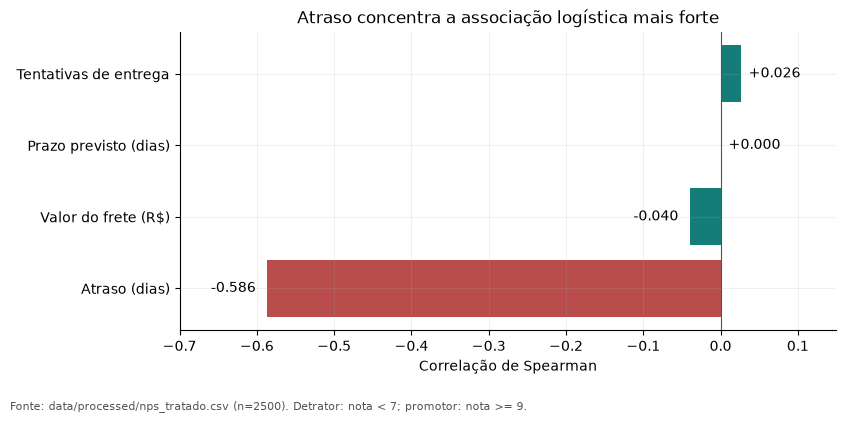

In [2]:
logistica = {
    "delivery_time_days": "Prazo previsto (dias)",
    "delivery_delay_days": "Atraso (dias)",
    "delivery_attempts": "Tentativas de entrega",
    "freight_value": "Valor do frete (R$)",
}
associacoes = pd.Series({nome: spearmanr(df[col], df["nps_score"]).statistic
                         for col, nome in logistica.items()}).sort_values()
display(associacoes.rename("Spearman com a nota").to_frame().round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(associacoes.index, associacoes.values,
        color=[VERMELHO if x < -0.1 else TURQUESA for x in associacoes.values])
ax.axvline(0, color="#555555", lw=0.8)
ax.set(xlabel="Correlação de Spearman", title="Atraso concentra a associação logística mais forte")
ax.set_xlim(-0.7, 0.15)
for i, valor in enumerate(associacoes.values):
    ax.text(valor - 0.015 if valor < 0 else valor + 0.01, i, f"{valor:+.3f}",
            ha="right" if valor < 0 else "left", va="center")
salvar(fig, "logistica_correlacoes.png")

O atraso tem associação negativa moderada com a nota (ρ = −0,586). Prazo previsto, tentativas e frete apresentam correlações isoladas próximas de zero nesta base; isso não prova ausência de relação em subgrupos nem em outros períodos.

## 3. Atraso, volume e distribuição das notas

Comparamos a quantidade de pedidos, a nota média e a taxa de detratores por faixa. A figura de distribuição preserva a variação individual que uma média pode esconder.

,pedidos,nota_media,detratores,detratores_pct
faixa_atraso,,,,
0,277,6.86,143,51.62
1,615,5.55,455,73.98
2,646,4.58,568,87.93
3–4,795,3.10,776,97.61
5+,167,1.28,167,100.00


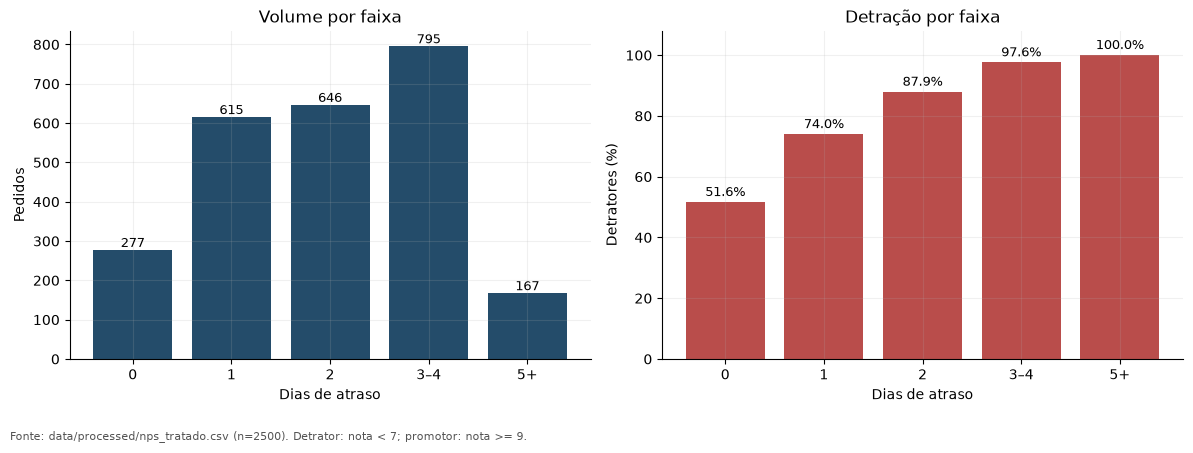

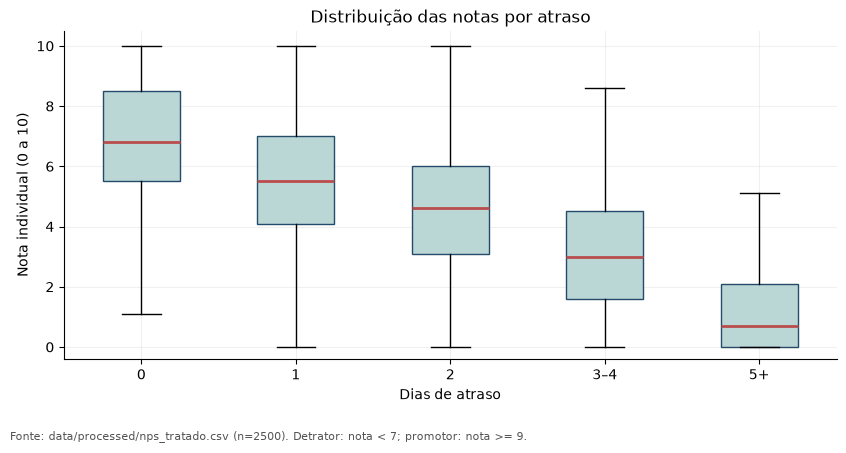

In [3]:
faixas = ["0", "1", "2", "3–4", "5+"]
df["faixa_atraso"] = pd.cut(df["delivery_delay_days"],
                            [-1, 0, 1, 2, 4, np.inf], labels=faixas)
atraso = df.groupby("faixa_atraso", observed=True).agg(
    pedidos=("nps_score", "size"), nota_media=("nps_score", "mean"),
    detratores=("is_detractor", "sum"))
atraso["detratores_pct"] = 100 * atraso["detratores"] / atraso["pedidos"]
display(atraso.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(atraso))
ax1.bar(x, atraso["pedidos"], color=AZUL)
ax1.set(xticks=x, xticklabels=faixas, xlabel="Dias de atraso", ylabel="Pedidos",
        title="Volume por faixa")
for i, n in enumerate(atraso["pedidos"]):
    ax1.text(i, n + 8, str(n), ha="center", fontsize=9)
ax2.bar(x, atraso["detratores_pct"], color=VERMELHO)
ax2.set(xticks=x, xticklabels=faixas, xlabel="Dias de atraso",
        ylabel="Detratores (%)", ylim=(0, 108), title="Detração por faixa")
for i, row in enumerate(atraso.itertuples()):
    ax2.text(i, row.detratores_pct + 2, f"{row.detratores_pct:.1f}%",
             ha="center", fontsize=9)
salvar(fig, "logistica_detratores_por_atraso.png")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
series = [df.loc[df["faixa_atraso"] == faixa, "nps_score"] for faixa in faixas]
ax.boxplot(series, tick_labels=faixas, showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#bad6d5", "edgecolor": AZUL},
           medianprops={"color": VERMELHO, "linewidth": 2})
ax.set(xlabel="Dias de atraso", ylabel="Nota individual (0 a 10)", ylim=(-0.4, 10.5),
       title="Distribuição das notas por atraso")
salvar(fig, "logistica_distribuicao_notas_atraso.png")

Há 143 detratores em 277 pedidos sem atraso (51,62%), 455 em 615 com um dia (73,98%) e 568 em 646 com dois dias (87,93%). A nota média cai de 6,86 para 5,55 já no primeiro dia. O padrão continua nos atrasos maiores, mas faixas longas têm menos pedidos. Mesmo sem atraso, mais da metade dos pedidos é de detratores; há outras fontes de insatisfação.

## 4. Prazo previsto, tentativas e frete

O prazo previsto e o atraso são grandezas distintas. Agrupamos o prazo e o frete em faixas com volumes visíveis e mostramos tentativas de entrega por contagem observada.

Prazo previsto (dias)


,pedidos,nota_media,detratores_pct
faixa_prazo,,,
2–4,590,4.32,84.75
5–7,548,4.47,85.58
8–10,571,4.46,83.54
11–14,791,4.31,83.82


Tentativas de entrega


,pedidos,nota_media,detratores_pct
delivery_attempts,,,
1,824,4.35,84.22
2,838,4.26,86.75
3,838,4.52,82.10


Frete por quartil (Q1 = menor valor)


,pedidos,nota_media,detratores_pct
faixa_frete,,,
Q1,625,4.42,84.32
Q2,626,4.55,81.79
Q3,625,4.34,85.92
Q4,624,4.21,85.42


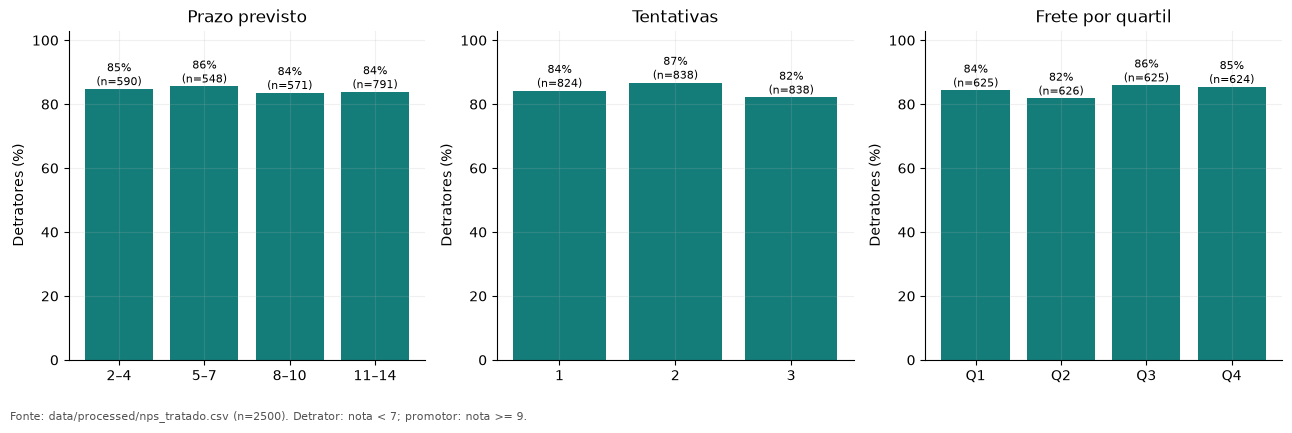

In [4]:
def resumir(frame, coluna):
    tabela = frame.groupby(coluna, observed=True).agg(
        pedidos=("nps_score", "size"), nota_media=("nps_score", "mean"),
        detratores_pct=("is_detractor", lambda s: 100 * s.mean()))
    return tabela.round(2)

df["faixa_prazo"] = pd.cut(df["delivery_time_days"], [0, 4, 7, 10, 14],
                           labels=["2–4", "5–7", "8–10", "11–14"])
df["faixa_frete"] = pd.qcut(df["freight_value"], 4,
                            labels=["Q1", "Q2", "Q3", "Q4"])
prazo = resumir(df, "faixa_prazo")
tentativas = resumir(df, "delivery_attempts")
frete = resumir(df, "faixa_frete")
print("Prazo previsto (dias)")
display(prazo)
print("Tentativas de entrega")
display(tentativas)
print("Frete por quartil (Q1 = menor valor)")
display(frete)

fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (titulo, tabela, rotulos) in zip(axs, [
    ("Prazo previsto", prazo, prazo.index.astype(str)),
    ("Tentativas", tentativas, tentativas.index.astype(str)),
    ("Frete por quartil", frete, frete.index.astype(str)),
]):
    x = np.arange(len(tabela))
    ax.bar(x, tabela["detratores_pct"], color=TURQUESA)
    ax.set(xticks=x, xticklabels=rotulos, ylim=(0, 103),
           ylabel="Detratores (%)", title=titulo)
    for i, row in enumerate(tabela.itertuples()):
        ax.text(i, row.detratores_pct + 1.2,
                f"{row.detratores_pct:.0f}%" + chr(10) + f"(n={row.pedidos})",
                ha="center", fontsize=8)
salvar(fig, "logistica_prazo_tentativas_frete.png")

As taxas de detratores por prazo previsto variam aproximadamente de 83,5% a 85,6%; por número de tentativas, de 82,1% a 86,8%; por quartil de frete, de 81,8% a 85,9%. Nesta base, essas diferenças são menores que o gradiente observado para atraso. Não há evidência, nesta análise isolada, de um limite nítido para tentativas ou frete.

## 5. Há um ponto de ruptura?

Um dia de atraso já distingue um grupo numeroso com maior taxa de detratores. A piora prossegue após esse dia, sem uma descontinuidade única que permita afirmar um ponto de ruptura causal. A comparação abaixo quantifica as duas primeiras transições e usa reamostragem apenas para mostrar a precisão exploratória da diferença de médias.

In [5]:
for minimo, maximo in [(0, 1), (1, 2)]:
    a = df.loc[df["delivery_delay_days"] == minimo]
    b = df.loc[df["delivery_delay_days"] == maximo]
    print(f"{minimo} → {maximo} dia(s): "
          f"{len(a)} vs. {len(b)} pedidos; "
          f"detração {100*a['is_detractor'].mean():.1f}% vs. "
          f"{100*b['is_detractor'].mean():.1f}%; "
          f"diferença de nota média {b['nps_score'].mean()-a['nps_score'].mean():+.2f}")

sem_atraso = df.loc[df["delivery_delay_days"] == 0, "nps_score"].to_numpy()
um_dia = df.loc[df["delivery_delay_days"] == 1, "nps_score"].to_numpy()
rng = np.random.default_rng(42)
amostras = np.array([
    rng.choice(um_dia, len(um_dia), replace=True).mean()
    - rng.choice(sem_atraso, len(sem_atraso), replace=True).mean()
    for _ in range(2000)
])
print("Diferença média (1 dia − 0):", round(um_dia.mean()-sem_atraso.mean(), 2))
print("Intervalo bootstrap exploratório (95%):", np.quantile(amostras, [.025, .975]).round(2))

0 → 1 dia(s): 277 vs. 615 pedidos; detração 51.6% vs. 74.0%; diferença de nota média -1.31
1 → 2 dia(s): 615 vs. 646 pedidos; detração 74.0% vs. 87.9%; diferença de nota média -0.97
Diferença média (1 dia − 0): -1.31
Intervalo bootstrap exploratório (95%): [-1.61 -1.02]


## 6. Conclusões para a operação

1. **Monitorar a partir do primeiro dia fora do prazo.** A taxa de detratores passa de 51,6% sem atraso para 74,0% com um dia, em grupos com 277 e 615 pedidos. Vale testar comunicação antecipada e correção de entrega, medindo alcance, custo e satisfação.
2. **Acompanhar a progressão do atraso.** Com dois dias, a taxa atinge 87,9%; com três ou quatro, 97,6%. Uma triagem pode priorizar pedidos que acumulam dias fora do prazo, sempre considerando o volume de cada faixa.
3. **Não definir uma política só por frete, tentativas ou prazo previsto.** As diferenças isoladas dessas variáveis são pequenas nesta base. Investigar subgrupos antes de transformar qualquer corte em regra de negócio.

Esta análise usa os 2.500 pedidos disponibilizados. A base não contém datas de eventos nem demonstra amostragem aleatória ou representatividade de outros períodos. O intervalo bootstrap pressupõe reamostragem dos pedidos observados e não corrige viés de seleção. Associação não comprova que reduzir atrasos, por si só, elevará o NPS; o impacto de uma ação deve ser avaliado em teste controlado.